In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sequence_jacobian as sj
try:
    from aquarel import load_theme
    theme = load_theme("minimal_light")
    theme.apply()
except ImportError:
    theme = None
print("Sequence-Jacobian loaded")

Sequence-Jacobian loaded


In [4]:
@sj.simple
def euler(beta, r, sigma, C):
    Euler = (beta*(1+r(1)))**(-sigma)*C(1) - C
    return Euler

In [5]:
@sj.simple
def bc(r, A, y, C):
    budget_constraint = (1+r) * A(-1) + y - C - A
    return budget_constraint

In [6]:
@sj.simple
def govt(B, r, G, Y):
    T = (1+r)*B(-1) + G - B
    y = Y - T
    Deficit = G - T
    return T, y, Deficit

In [7]:
@sj.simple
def ex_post_rate(r_ante):
    r = r_ante(-1)
    return r

In [9]:
@sj.simple
def mkt_clearing_prod(A, Y, C, G, B, r, beta):
    asset_mkt = A - B
    goods_mkt = Y - C - G
    return asset_mkt, goods_mkt

In [10]:
@sj.simple
def vpclear(phip, Pistar, ep, Pi, vp):
    vpres = ((1-phip) * Pistar**(-ep) * Pi**(ep)) + (Pi**(ep) * phip * vp(-1)) - vp
    return vpres

@sj.simple
def firm(ep, Pi, x1, x2, mc, C, sigma, phip, beta, Pistar, eta, chi, vp, Z):
    w = mc*Z
    L = (w*C**(-1)/chi)**(1/eta)
    Y = Z*L/vp
    x1res = (C**(-sigma) * mc * Y) + (phip * beta * Pi(1)**(ep) * x1(1)) - x1
    x2res = (C**(-sigma) * Y) + (phip * beta * Pi(1)**(ep-1) * x2(1)) - x2
    mcres = ep/(ep-1) * Pi * ((C**(-sigma) * mc * Y) + (phip * beta * Pi(1)**(ep) * x1(1)))/((C**(-sigma) * Y) + (phip * beta * Pi(1)**(ep-1) * x2(1))) - Pistar
    return mcres, x1res, x2res, L, Y, w

In [11]:
@sj.simple
def prices(phip, Pistar, ep, Pi):
    pres = (1-phip) * Pistar**(1-ep) + phip - Pi**(1-ep)
    return pres

In [12]:
@sj.simple
def fed(Pi, ishock, rss, phipi, rho, i):
    ires = (1-rho)*rss + rho*i(-1) + (1-rho)*phipi*(Pi-1) + ishock - i
    r_ante = i - (Pi(1)-1)
    return ires, r_ante

In [13]:
ra_prod = sj.create_model([euler, bc, ex_post_rate, mkt_clearing_prod, govt,
                           firm, fed, vpclear, prices], name="RA Prod")
print("INPUTS:", ra_prod.inputs)
print("OUTPUTS:", ra_prod.outputs)

INPUTS: ['beta', 'sigma', 'C', 'A', 'G', 'B', 'ep', 'Pi', 'x1', 'x2', 'mc', 'phip', 'Pistar', 'eta', 'chi', 'vp', 'Z', 'ishock', 'rss', 'phipi', 'rho', 'i']
OUTPUTS: ['Euler', 'budget_constraint', 'r', 'asset_mkt', 'goods_mkt', 'T', 'y', 'Deficit', 'mcres', 'x1res', 'x2res', 'L', 'Y', 'w', 'ires', 'r_ante', 'vpres', 'pres']


In [14]:
cal_prod = {'G': 0.2, 'B': 0.5, 'sigma': 1., 'chi': 1., 'rss': 0.02, 'eta': 1.,
            'phip': 0.75, 'ep': 11, 'phipi': 1.5, 'Pi': 1., 'ishock': 0.,
            'Z': 1., 'rho': 0.8}
ss_prod = ra_prod.solve_steady_state(
    cal_prod,
    {'beta': 0.995, 'A': .5, 'x1': 4.65, 'x2': 5.12, 'vp': 1.,
     'Pistar': 1., 'mc': 0.909091, 'C': 0.836, 'i': 0.01},
    {'asset_mkt': 0., 'budget_constraint': 0., 'x1res': 0., 'x2res': 0.,
     'vpres': 0., 'Euler': 0., 'mcres': 0., 'pres': 0., 'ires': 0.})
for key in ['beta','A','G','Y','C','T','L','mc','i','Pi','goods_mkt']:
    print(f'{key:>12}: {ss_prod[key]:.8f}')
assert abs(ss_prod['goods_mkt']) < 1e-6
assert abs(ss_prod['asset_mkt']) < 1e-6

        beta: 0.98039216
           A: 0.50000000
           G: 0.20000000
           Y: 1.05869229
           C: 0.85869229
           T: 0.21000000
           L: 1.05869229
          mc: 0.90909091
           i: 0.02000000
          Pi: 1.00000000
   goods_mkt: -0.00000000


In [15]:
T = 300
unknowns = ['A', 'x1', 'x2', 'vp', 'Pistar', 'mc', 'C', 'i', 'Pi']
targets = ['asset_mkt', 'budget_constraint', 'x1res', 'x2res',
           'vpres', 'Euler', 'mcres', 'pres', 'ires']
assert len(unknowns) == len(targets)
print('Number of unknown paths:', len(unknowns))

Number of unknown paths: 9


In [16]:
dg = 0.01 * 0.6 ** np.arange(T)
irf_g = ra_prod.solve_impulse_linear(ss_prod, unknowns, targets, {'G': dg})
print(irf_g)

<ImpulseDict: ['G', 'A', 'x1', 'x2', 'vp', 'Pistar', 'mc', 'C', 'i', 'Pi', 'Euler', 'budget_constraint', 'r', 'asset_mkt', 'goods_mkt', 'T', 'y', 'Deficit', 'mcres', 'x1res', 'x2res', 'L', 'Y', 'w', 'ires', 'r_ante', 'vpres', 'pres']>


In [17]:
da = 0.0065 * 0.9 ** np.arange(T)
irf_z = ra_prod.solve_impulse_linear(ss_prod, unknowns, targets, {'Z': da})
print(irf_z)

<ImpulseDict: ['Z', 'A', 'x1', 'x2', 'vp', 'Pistar', 'mc', 'C', 'i', 'Pi', 'Euler', 'budget_constraint', 'r', 'asset_mkt', 'goods_mkt', 'T', 'y', 'Deficit', 'mcres', 'x1res', 'x2res', 'L', 'Y', 'w', 'ires', 'r_ante', 'vpres', 'pres']>


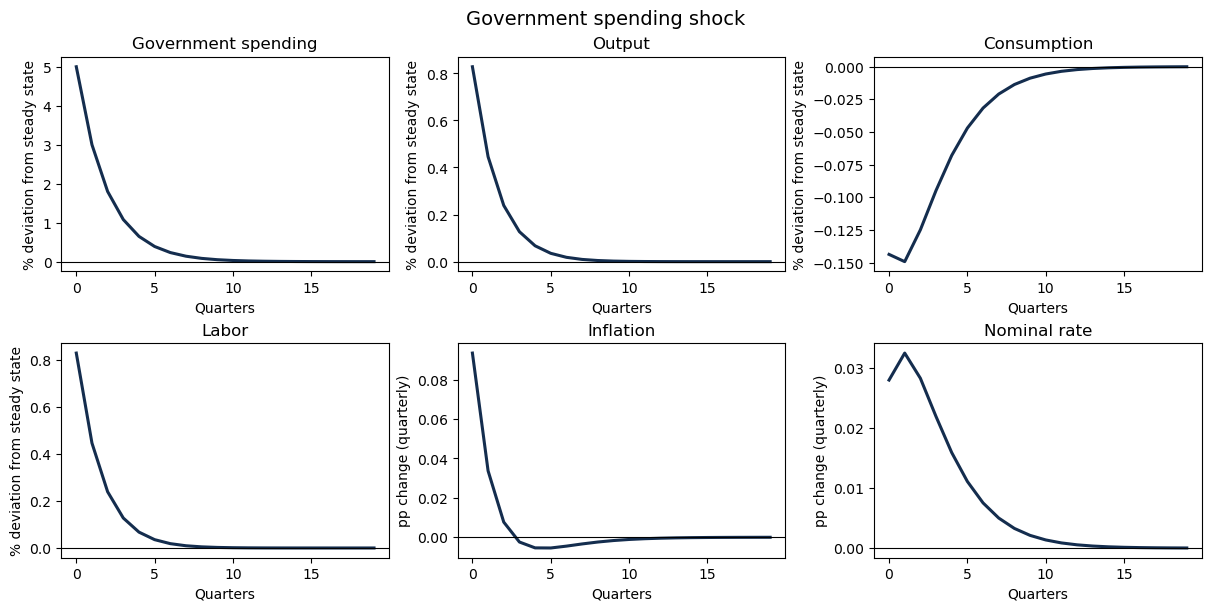

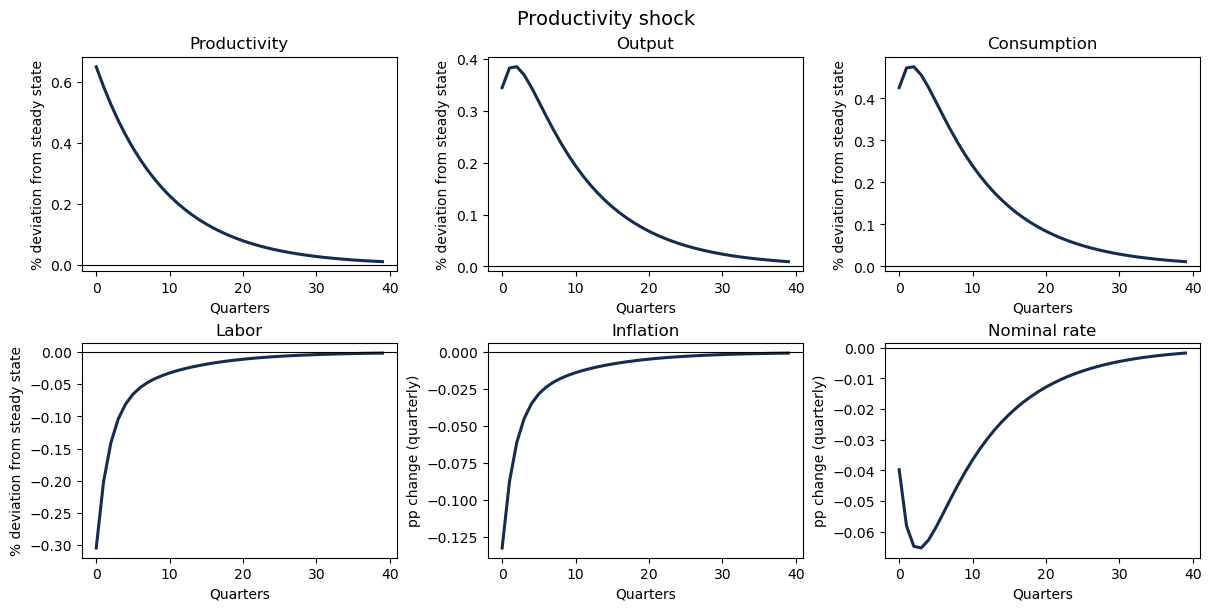

In [21]:
def plot_irf(irf, ss, shock_name, horizon=40):
    keys = ['G' if shock_name=='Government spending' else 'Z',
            'Y','C','L','Pi','i']
    names = ['Government spending' if shock_name=='Government spending' else 'Productivity',
             'Output','Consumption','Labor','Inflation','Nominal rate']

    fig, axes = plt.subplots(2, 3, figsize=(12,6), constrained_layout=True)

    for ax, k, name in zip(axes.flat, keys, names):
        series = np.asarray(irf[k][:horizon])

        if k in ('Pi','i'):
            response = 100 * series
            unit = 'pp change (quarterly)'
        else:
            response = 100 * series / float(ss[k])
            unit = '% deviation from steady state'

        ax.plot(
            np.arange(len(response)),
            response,
            color='#142D4E',  # Deep navy
            linewidth=2.2
        )

        ax.axhline(0, linewidth=0.8, color='black')
        ax.set(title=name, xlabel='Quarters', ylabel=unit)

    fig.suptitle(shock_name + ' shock', fontsize=14)
    plt.show()


plot_irf(irf_g, ss_prod, 'Government spending', horizon=20)
plot_irf(irf_z, ss_prod, 'Productivity', horizon=40)

In [22]:
H=19
multiplier=np.sum(irf_g['Y'][:H+1])/np.sum(irf_g['G'][:H+1])
print(f'Cumulative government spending multiplier (0-{H} quarters): {multiplier:.4f}')

Cumulative government spending multiplier (0-19 quarters): 0.7535
